# 02 — Exploratory Analysis

Descriptive analysis of the analysis-ready sample (observed target only). No model is
trained here. Correlations are descriptive, not causal.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().resolve()
while not (ROOT / "src").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))

import hashlib
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

from sm_project import config, data, features, modeling, viz

config.ensure_output_dirs()
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)
print("Project root:", ROOT)
print("Fixed seed:", config.SEED)

Project root: /Users/dhanudriya/Lecturer/ML-project-1
Fixed seed: 42


In [2]:
df = data.load_data()
analysis = data.eligible_sample(df)
print("Rows in raw file:", len(df))
print("Rows with observed target (analysis sample):", len(analysis))
print("Excluded for missing target:", len(df) - len(analysis))
display(analysis[config.TARGET].describe().to_frame().T)

Rows in raw file: 4500
Rows with observed target (analysis sample): 4415
Excluded for missing target: 85


,count,mean,std,min,25%,50%,75%,max
Academic_Performance_GPA,4415.0,3.429282,0.392662,1.9,3.2,3.46,3.72,4.0


## 1. Target distribution

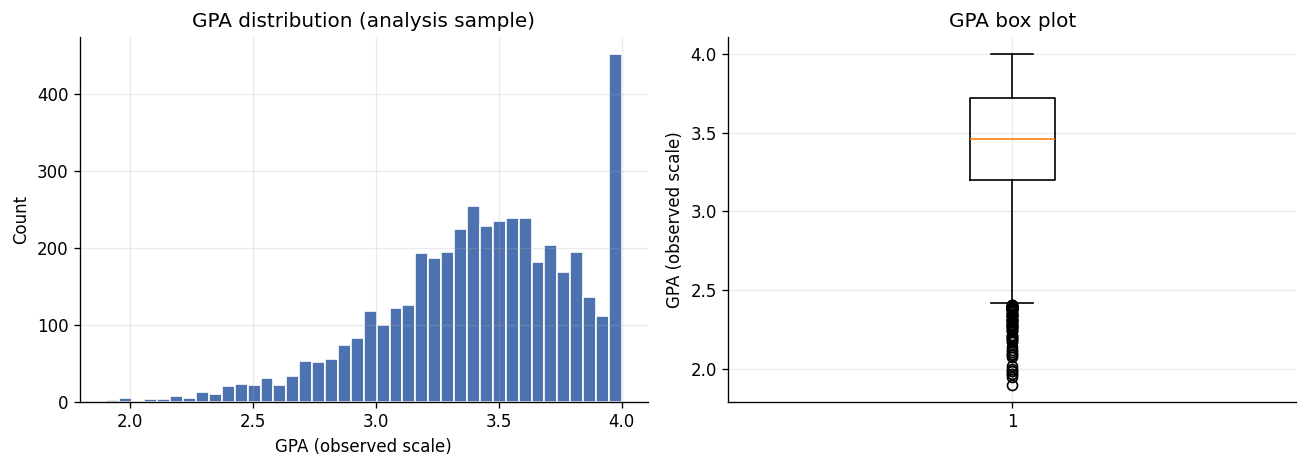

PosixPath('/Users/dhanudriya/Lecturer/ML-project-1/outputs/figures/02_target_distribution.png')

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].hist(analysis[config.TARGET], bins=40, color="#4C72B0", edgecolor="white")
axes[0].set_title("GPA distribution (analysis sample)")
axes[0].set_xlabel("GPA (observed scale)")
axes[0].set_ylabel("Count")
axes[1].boxplot(analysis[config.TARGET], vert=True)
axes[1].set_title("GPA box plot")
axes[1].set_ylabel("GPA (observed scale)")
viz.finish_figure(fig, "02_target_distribution.png")

## 2. Numeric predictor distributions

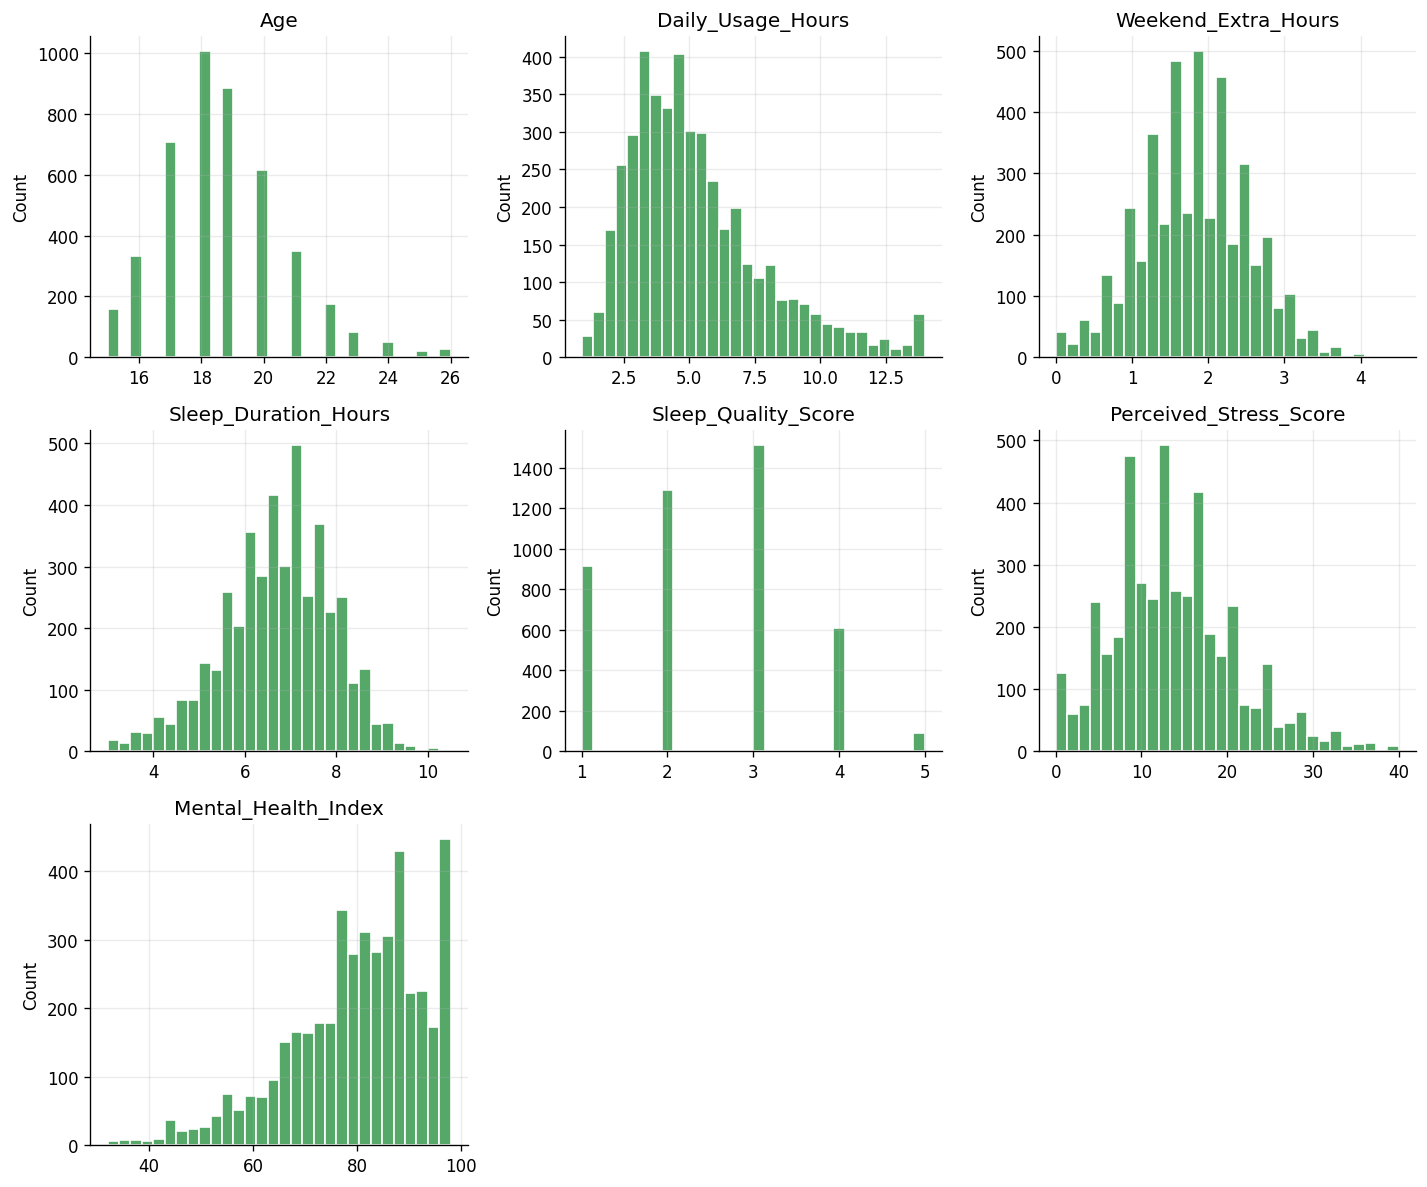

PosixPath('/Users/dhanudriya/Lecturer/ML-project-1/outputs/figures/02_numeric_histograms.png')

In [4]:
numeric_cols = [c for c in config.NUMERIC_FEATURES if c in analysis.columns]
fig, axes = plt.subplots(3, 3, figsize=(12, 10))
for ax, column in zip(axes.ravel(), numeric_cols):
    ax.hist(analysis[column].dropna(), bins=30, color="#55A868", edgecolor="white")
    ax.set_title(column)
    ax.set_ylabel("Count")
for ax in axes.ravel()[len(numeric_cols):]:
    ax.axis("off")
viz.finish_figure(fig, "02_numeric_histograms.png")

## 3. Numeric predictor box plots

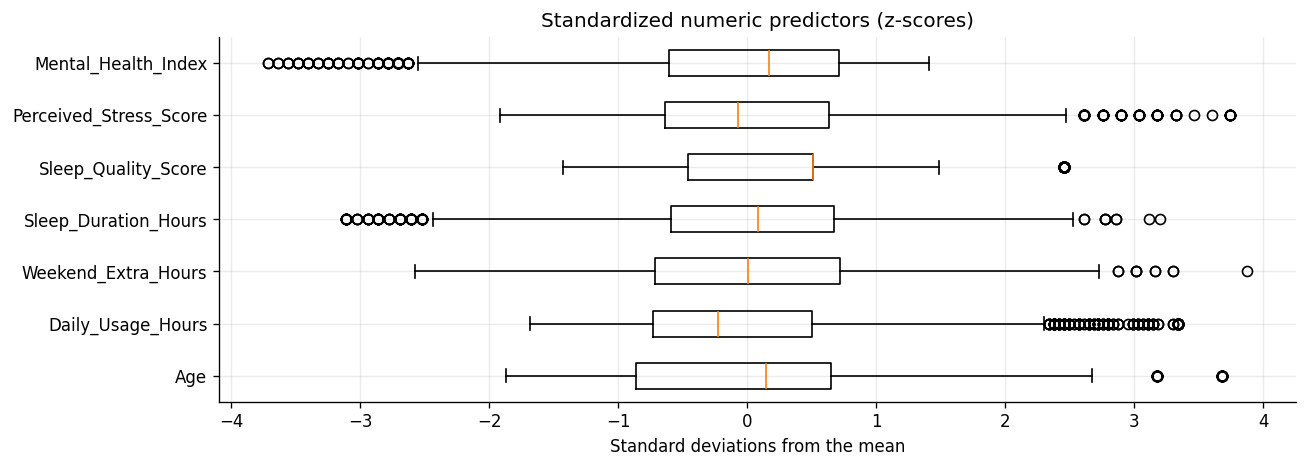

PosixPath('/Users/dhanudriya/Lecturer/ML-project-1/outputs/figures/02_numeric_boxplots.png')

In [5]:
scaled = analysis[numeric_cols].copy()
z = (scaled - scaled.mean()) / scaled.std(ddof=0)
fig, ax = plt.subplots(figsize=(11, 4))
ax.boxplot([z[c].dropna() for c in numeric_cols], tick_labels=numeric_cols, vert=False)
ax.set_title("Standardized numeric predictors (z-scores)")
ax.set_xlabel("Standard deviations from the mean")
viz.finish_figure(fig, "02_numeric_boxplots.png")

## 4. Correlation structure

Interpretation is intentionally cautious: the dataset contains strong predictor-predictor
correlations, so individual coefficients and importances may be unstable.

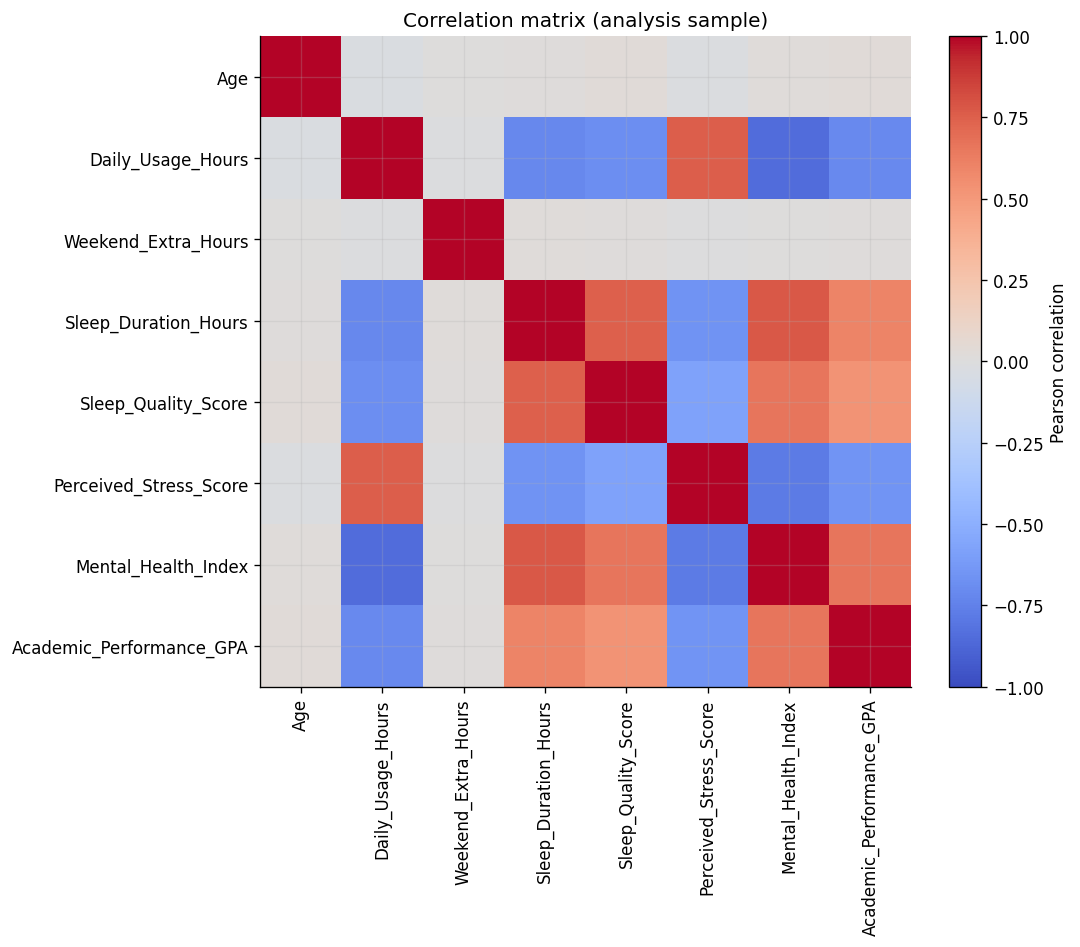

In [6]:
correlation = analysis.select_dtypes(include="number").corr()
fig, ax = plt.subplots(figsize=(10, 8))
im = ax.imshow(correlation, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(correlation.columns)))
ax.set_xticklabels(correlation.columns, rotation=90)
ax.set_yticks(range(len(correlation.columns)))
ax.set_yticklabels(correlation.columns)
ax.set_title("Correlation matrix (analysis sample)")
fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04, label="Pearson correlation")
viz.finish_figure(fig, "02_correlation_heatmap.png")
correlation.to_csv(config.TABLES_DIR / "02_correlation_matrix.csv")

## 5. GPA by categorical variables

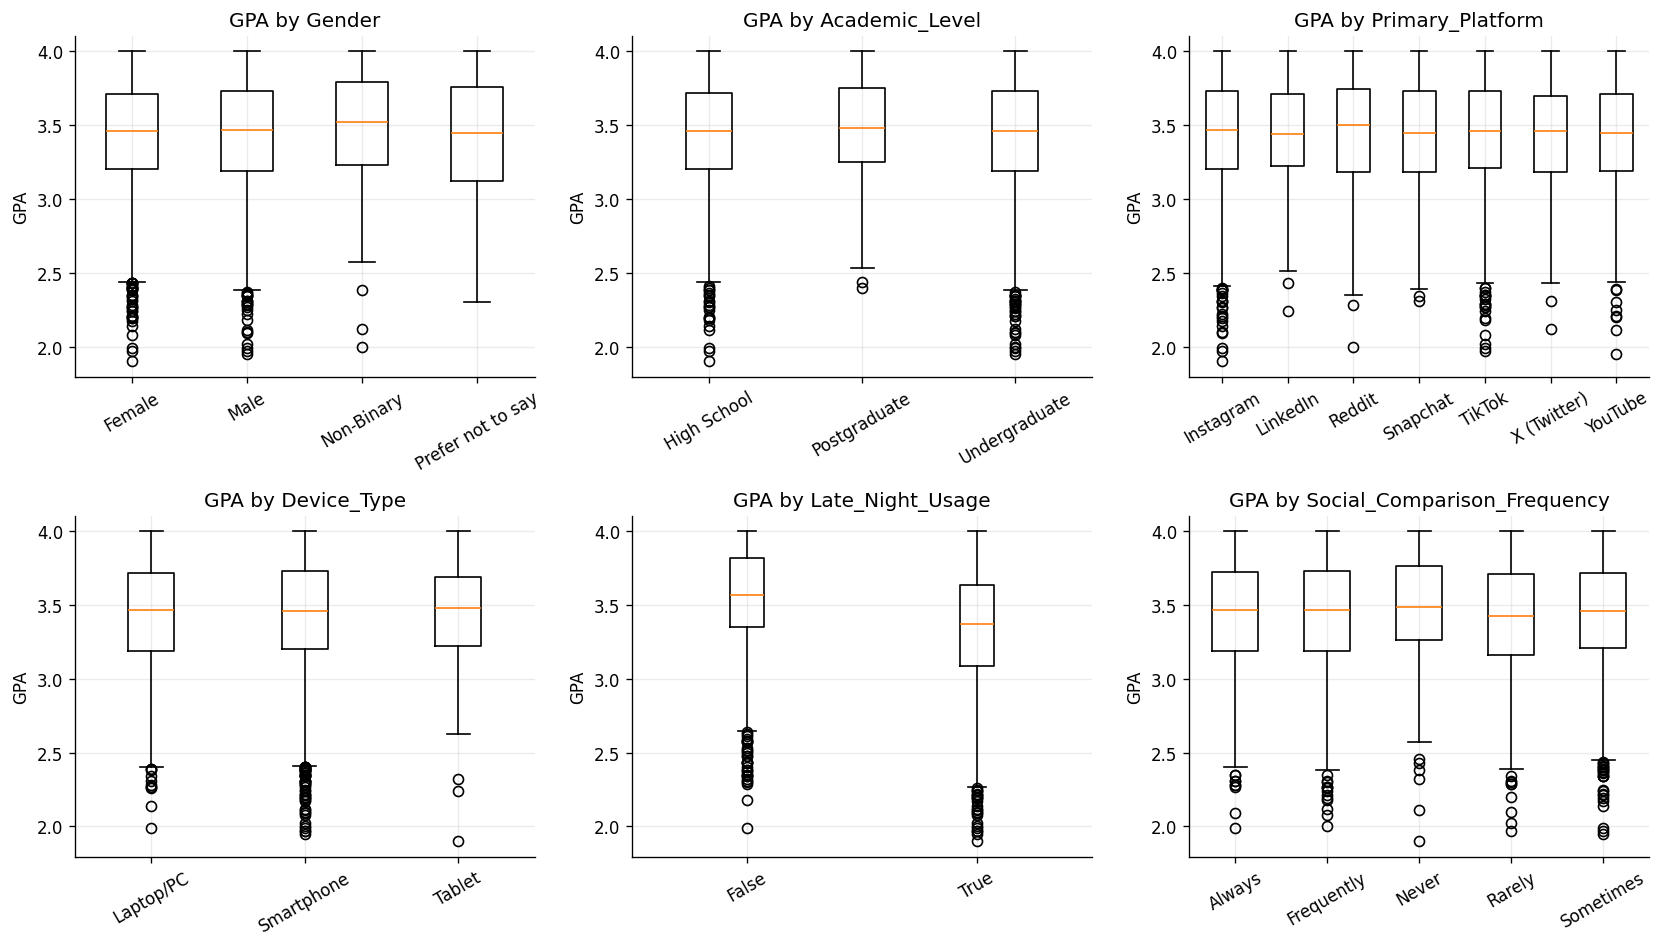

,count,mean,std
Late_Night_Usage,,,
False,1824,3.548,0.345
True,2591,3.346,0.402


In [7]:
cat_cols = [c for c in config.CATEGORICAL_FEATURES if c in analysis.columns]
fig, axes = plt.subplots(2, 3, figsize=(14, 8))
for ax, column in zip(axes.ravel(), cat_cols):
    groups = [g[config.TARGET].dropna().values for _, g in analysis.groupby(column)]
    labels = [str(k) for k, _ in analysis.groupby(column)]
    ax.boxplot(groups, tick_labels=labels)
    ax.set_title(f"GPA by {column}")
    ax.set_ylabel("GPA")
    ax.tick_params(axis="x", rotation=30)
for ax in axes.ravel()[len(cat_cols):]:
    ax.axis("off")
viz.finish_figure(fig, "02_gpa_by_category.png")

by_category = (
    analysis.groupby("Late_Night_Usage")[config.TARGET]
    .agg(["count", "mean", "std"])
    .round(3)
)
display(by_category)
by_category.to_csv(config.TABLES_DIR / "02_gpa_by_late_night.csv")

## 6. GPA against key numeric predictors

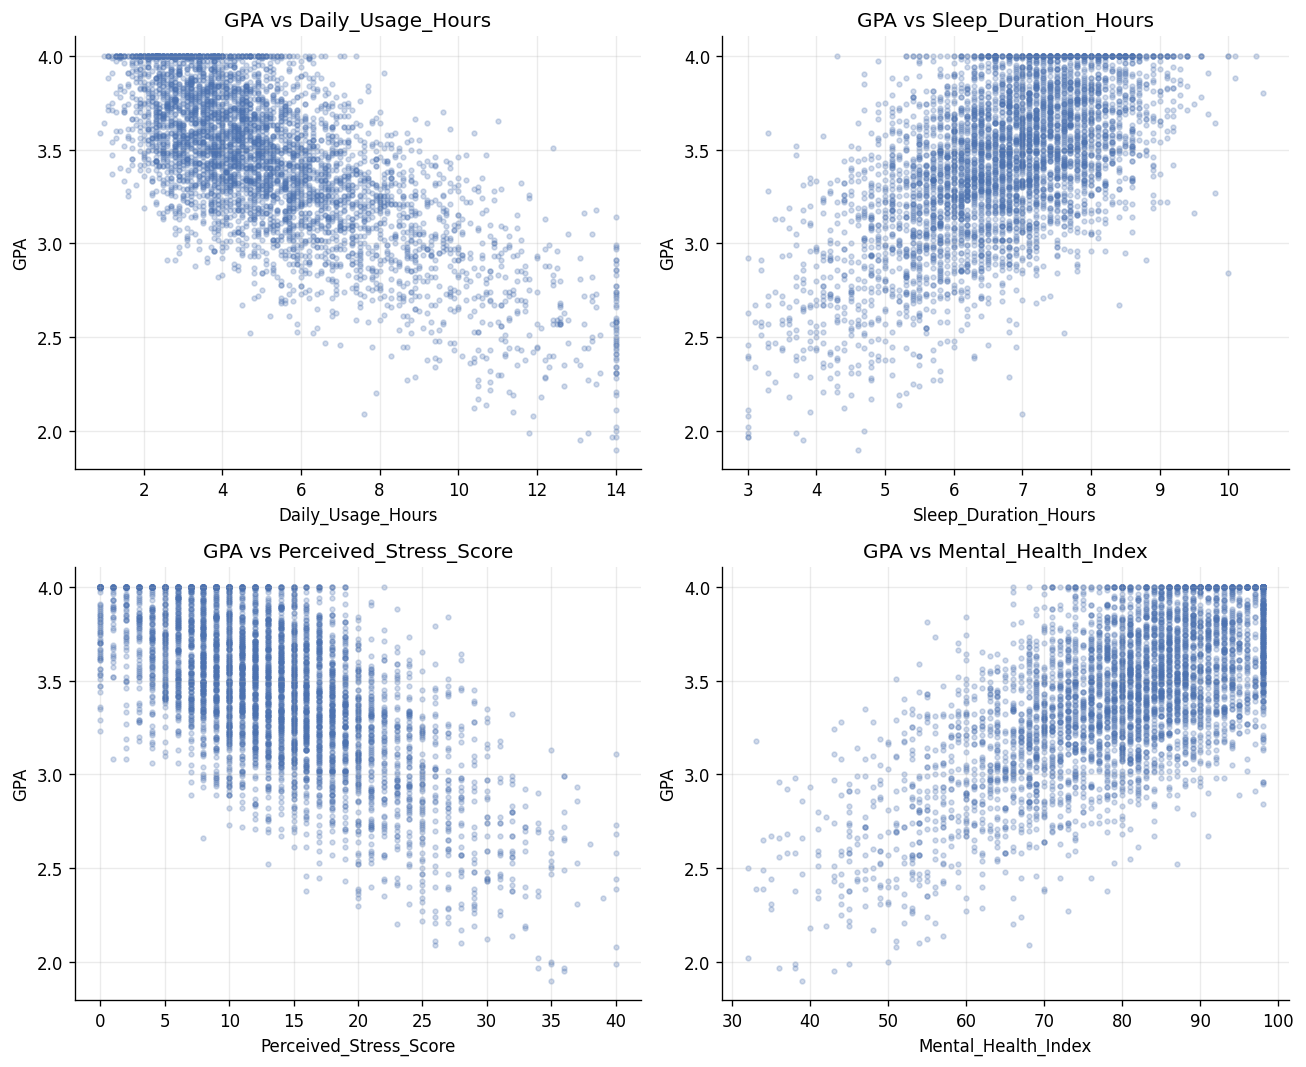

PosixPath('/Users/dhanudriya/Lecturer/ML-project-1/outputs/figures/02_gpa_scatterplots.png')

In [8]:
key_predictors = ["Daily_Usage_Hours", "Sleep_Duration_Hours",
                  "Perceived_Stress_Score", "Mental_Health_Index"]
fig, axes = plt.subplots(2, 2, figsize=(11, 9))
for ax, column in zip(axes.ravel(), key_predictors):
    plot_df = analysis[[column, config.TARGET]].dropna()
    ax.scatter(plot_df[column], plot_df[config.TARGET], s=8, alpha=0.25, color="#4C72B0")
    ax.set_xlabel(column)
    ax.set_ylabel("GPA")
    ax.set_title(f"GPA vs {column}")
viz.finish_figure(fig, "02_gpa_scatterplots.png")

## 7. Exploratory summary

In [9]:
target_corr = (
    analysis.select_dtypes(include="number").corr()[config.TARGET]
    .drop(config.TARGET).sort_values(key=np.abs, ascending=False)
)
display(target_corr.to_frame("pearson_r"))
target_corr.to_frame("pearson_r").to_csv(config.TABLES_DIR / "02_target_correlations.csv")

report_lines = [
    "# Exploratory Analysis Summary",
    "",
    f"- Analysis sample: {len(analysis):,} records with an observed target "
    f"({len(df) - len(analysis)} excluded for missing target).",
    f"- GPA: mean {analysis[config.TARGET].mean():.3f}, "
    f"SD {analysis[config.TARGET].std():.3f}, range "
    f"{analysis[config.TARGET].min():.2f}-{analysis[config.TARGET].max():.2f}.",
    f"- Strongest absolute correlations with GPA: "
    + ", ".join(f"{k} ({v:.2f})" for k, v in target_corr.head(5).items()) + ".",
    f"- Late_Night_Usage mean GPA: "
    + "; ".join(f"{k}={v:.3f}" for k, v in analysis.groupby('Late_Night_Usage')[config.TARGET].mean().items()) + ".",
    "",
    "## Interpretation limits",
    "",
    "- Correlations describe this file only and are not causal effects.",
    "- Daily usage, sleep, stress, and mental health are strongly inter-correlated, so "
    "univariate correlations overstate unique contributions.",
    "- Most categorical variables (platform, device, gender, academic level, comparison frequency) "
    "show little separation in GPA; Late_Night_Usage shows a modest difference, although its unique "
    "contribution is small once numeric usage and sleep variables are included in the models.",
    "- The analysis sample contains only records with an observed target; predictor missingness "
    "is handled later inside model pipelines.",
]
eda_text = "\n".join(report_lines)
(config.REPORTS_DIR / "02_exploratory_analysis.md").write_text(eda_text, encoding="utf-8")
display(Markdown(eda_text))

,pearson_r
Daily_Usage_Hours,-0.710057
Mental_Health_Index,0.659419
Perceived_Stress_Score,-0.650921
Sleep_Duration_Hours,0.595263
Sleep_Quality_Score,0.529270
Age,0.028110
Weekend_Extra_Hours,0.012275


# Exploratory Analysis Summary

- Analysis sample: 4,415 records with an observed target (85 excluded for missing target).
- GPA: mean 3.429, SD 0.393, range 1.90-4.00.
- Strongest absolute correlations with GPA: Daily_Usage_Hours (-0.71), Mental_Health_Index (0.66), Perceived_Stress_Score (-0.65), Sleep_Duration_Hours (0.60), Sleep_Quality_Score (0.53).
- Late_Night_Usage mean GPA: False=3.548; True=3.346.

## Interpretation limits

- Correlations describe this file only and are not causal effects.
- Daily usage, sleep, stress, and mental health are strongly inter-correlated, so univariate correlations overstate unique contributions.
- Most categorical variables (platform, device, gender, academic level, comparison frequency) show little separation in GPA; Late_Night_Usage shows a modest difference, although its unique contribution is small once numeric usage and sleep variables are included in the models.
- The analysis sample contains only records with an observed target; predictor missingness is handled later inside model pipelines.